# Time Series Practice 3

Notebook này chỉ đọc official artifacts để **trình bày kết quả**; không chạy lại data pipeline, training hoặc prediction.

## Phase 0 — Tổng quan bài toán

| Thành phần | Nội dung |
|---|---|
| **What** | Dự báo mức tiêu thụ điện theo giờ, target là `AEP_MW`. |
| **Why** | Đánh giá khả năng dùng Machine Learning cho bài toán dự báo phụ tải và hỗ trợ lập kế hoạch vận hành. |
| **Who** | Người phân tích dữ liệu và đơn vị cần theo dõi/dự báo nhu cầu điện. |
| **Where** | Chuỗi AEP từ [Kaggle — Hourly Energy Consumption, AEP_hourly.csv](https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption?select=AEP_hourly.csv); source file không cung cấp metadata địa lý chi tiết cho từng timestamp. |
| **When** | Từ `2004-10-01 01:00:00` đến `2018-08-03 00:00:00`, tần suất theo giờ. |
| **How** | Data preparation → lag/rolling features → temporal CV → model lock → one-step và recursive 24-hour evaluation → interpretation. |

### Data contract

| Thành phần | Giá trị |
|---|---|
| Raw input | `datasets/raw/AEP_hourly.csv` |
| Schema | `Datetime`, `AEP_MW` |
| Target | `AEP_MW` |
| Frequency | Hourly |
| Timezone policy | Giữ timezone-naive vì source không có timezone hoặc UTC offset |
| Final output | Model lock, forecast metrics, feature importance và final analysis |

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
result_dir = project_root / "outputs/results"
processed_path = project_root / "datasets/processed/aep_hourly_prepared.csv"
feature_config_path = project_root / "config/feature_engineering.json"
validation_config_path = project_root / "config/validation.json"
audit_paths = {
    "phase_01": result_dir / "phase_01_data_quality.json",
    "phase_02": result_dir / "phase_02_feature_quality.json",
    "phase_03": result_dir / "phase_03_supervised_quality.json",
    "phase_04": result_dir / "phase_04_split_audit.json",
}
phase_05_cv_path = result_dir / "phase_05_cv_results.json"
phase_05_lock_path = result_dir / "phase_05_model_lock.json"
phase_06_one_step_path = result_dir / "phase_06_one_step_metrics.json"
phase_06_multistep_path = result_dir / "phase_06_multistep_metrics.json"
phase_06_audit_path = result_dir / "phase_06_evaluation_audit.json"
phase_07_importance_path = result_dir / "phase_07_feature_importance.csv"
phase_07_comparison_path = result_dir / "phase_07_comparison_summary.csv"
phase_07_summary_path = result_dir / "phase_07_interpretation_summary.json"
phase_07_analysis_path = result_dir / "phase_07_final_analysis.md"
phase_07_figure_path = project_root / "outputs/figures/phase_07_top20_feature_importance.png"
phase_06_figure_paths = [
    project_root / "outputs/figures/phase_06_one_step_full_test.png",
    project_root / "outputs/figures/phase_06_one_step_first_14_days.png",
    project_root / "outputs/figures/phase_06_multistep_error_by_horizon.png",
]
required_paths = [processed_path, feature_config_path, validation_config_path, phase_05_cv_path, phase_05_lock_path, phase_06_one_step_path, phase_06_multistep_path, phase_06_audit_path, phase_07_importance_path, phase_07_comparison_path, phase_07_summary_path, phase_07_analysis_path, phase_07_figure_path, *phase_06_figure_paths, *audit_paths.values()]
missing_paths = [str(path) for path in required_paths if not path.exists()]
assert not missing_paths, f"Thiếu presentation artifact: {missing_paths}"
audits = {}
for phase_name, path in audit_paths.items():
    with path.open(encoding="utf-8") as file:
        audits[phase_name] = json.load(file)
    assert audits[phase_name]["status"] == "PASS"
with phase_05_cv_path.open(encoding="utf-8") as file:
    audits["phase_05_cv"] = json.load(file)
with phase_05_lock_path.open(encoding="utf-8") as file:
    audits["phase_05_lock"] = json.load(file)
with phase_06_one_step_path.open(encoding="utf-8") as file:
    audits["phase_06_one_step"] = json.load(file)
with phase_06_multistep_path.open(encoding="utf-8") as file:
    audits["phase_06_multistep"] = json.load(file)
with phase_06_audit_path.open(encoding="utf-8") as file:
    audits["phase_06_audit"] = json.load(file)
with phase_07_summary_path.open(encoding="utf-8") as file:
    audits["phase_07_summary"] = json.load(file)
assert audits["phase_05_cv"]["status"] == "PASS"
assert audits["phase_05_lock"]["status"] == "PASS"
assert audits["phase_06_one_step"]["status"] == "PASS"
assert audits["phase_06_multistep"]["status"] == "PASS"
assert audits["phase_06_audit"]["status"] == "PASS"
assert audits["phase_07_summary"]["status"] == "PASS"
with feature_config_path.open(encoding="utf-8") as file:
    feature_config = json.load(file)
with validation_config_path.open(encoding="utf-8") as file:
    validation_config = json.load(file)
df_prepared = pd.read_csv(processed_path)
print("Presentation artifacts: Phase 1–7 PASS")

Presentation artifacts: Phase 1–7 PASS


## Phase 1 — Data Preparation

### Mục tiêu

Chuẩn hóa raw data thành chuỗi thời gian theo giờ, bảo toàn dữ liệu nguồn và giữ lại các thời điểm thiếu dưới dạng `NaN` để không tạo giá trị quan sát giả.

### Luồng xử lý

`Đọc raw data` → `Chuẩn hóa Datetime` → `Tổng hợp timestamp trùng` → `Dựng timeline liên tục theo giờ` → `Gắn quality_flag`

### Dữ liệu đang được sử dụng

Hai góc nhìn dưới đây mô tả official prepared dataset: toàn bộ chuỗi để thấy mức biến động dài hạn và 14 ngày đầu để thấy nhịp thay đổi theo giờ.

,Thuộc tính,Giá trị
0,Khoảng thời gian,2004-10-01 01:00:00 → 2018-08-03 00:00:00
1,Tần suất,Theo giờ
2,Số timestamp,"121,296"
3,Target hợp lệ,"121,269"
4,Target thiếu,27
5,Trung bình AEP_MW,"15,499.65"
6,Trung vị AEP_MW,"15,310.00"
7,Độ lệch chuẩn,"2,591.32"
8,Min / Max,"9,581 / 25,695"


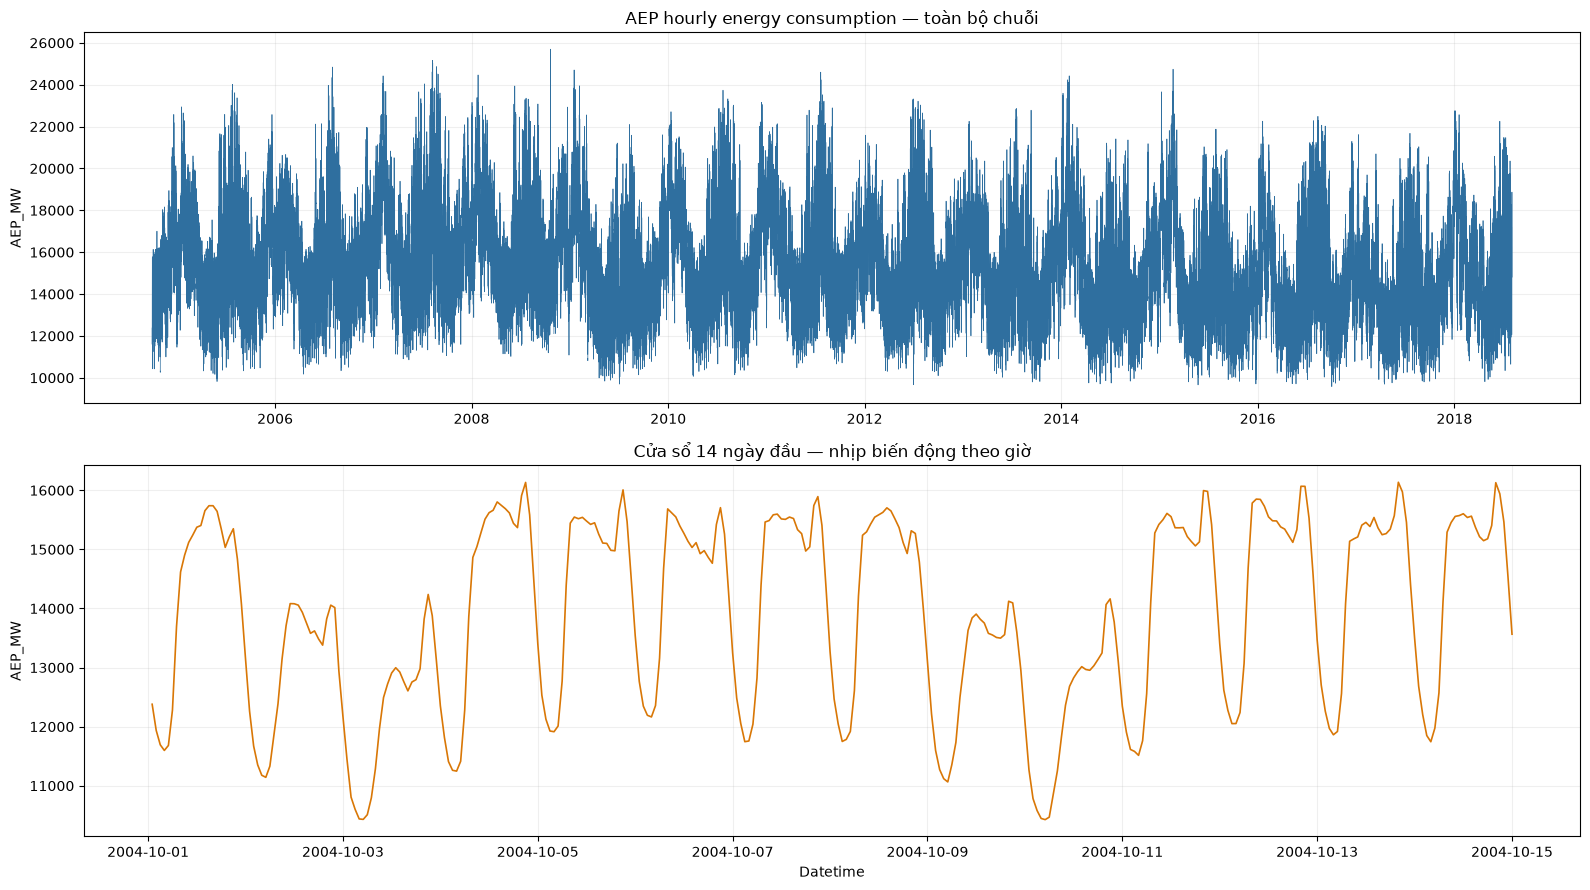

In [2]:
df_overview = df_prepared.loc[:, ["Datetime", "AEP_MW"]].copy()
df_overview["Datetime"] = pd.to_datetime(df_overview["Datetime"])
target_summary = df_overview["AEP_MW"].describe()
dataset_summary = pd.DataFrame(
    [
        ["Khoảng thời gian", f"{df_overview['Datetime'].min()} → {df_overview['Datetime'].max()}"],
        ["Tần suất", "Theo giờ"],
        ["Số timestamp", f"{len(df_overview):,}"],
        ["Target hợp lệ", f"{int(target_summary['count']):,}"],
        ["Target thiếu", f"{int(df_overview['AEP_MW'].isna().sum()):,}"],
        ["Trung bình AEP_MW", f"{target_summary['mean']:,.2f}"],
        ["Trung vị AEP_MW", f"{target_summary['50%']:,.2f}"],
        ["Độ lệch chuẩn", f"{target_summary['std']:,.2f}"],
        ["Min / Max", f"{target_summary['min']:,.0f} / {target_summary['max']:,.0f}"],
    ],
    columns=["Thuộc tính", "Giá trị"],
)
display(dataset_summary)

figure, axes = plt.subplots(2, 1, figsize=(16, 9))
axes[0].plot(df_overview["Datetime"], df_overview["AEP_MW"], color="#2f6f9f", linewidth=0.5)
axes[0].set_title("AEP hourly energy consumption — toàn bộ chuỗi")
axes[0].set_ylabel("AEP_MW")
axes[0].grid(alpha=0.2)
diagnostic_window = df_overview.head(24 * 14)
axes[1].plot(diagnostic_window["Datetime"], diagnostic_window["AEP_MW"], color="#d97706", linewidth=1.2)
axes[1].set_title("Cửa sổ 14 ngày đầu — nhịp biến động theo giờ")
axes[1].set_xlabel("Datetime")
axes[1].set_ylabel("AEP_MW")
axes[1].grid(alpha=0.2)
figure.tight_layout()
plt.show()

In [3]:
phase_01 = audits["phase_01"]
phase_01_summary = pd.DataFrame(
    [
        ["Raw — số dòng nguồn", phase_01["raw_rows"]],
        ["Prepared — số timestamp theo giờ", phase_01["prepared_rows"]],
        ["Bắt đầu", phase_01["prepared_time_start"]],
        ["Kết thúc", phase_01["prepared_time_end"]],
        ["Timestamp trùng trước xử lý", phase_01["duplicate_timestamps_before"]],
        ["Timestamp thiếu trước reindex", phase_01["missing_hourly_timestamps_before"]],
        ["Target thiếu sau reindex", phase_01["missing_AEP_MW"]],
        ["Timeline liên tục theo giờ", phase_01["timeline_continuous_hourly"]],
        ["Raw checksum không đổi", phase_01["raw_sha256_before"] == phase_01["raw_sha256_after"]],
        ["Trạng thái", phase_01["status"]],
    ],
    columns=["Chỉ số", "Kết quả"],
)
phase_01_quality = pd.DataFrame(
    [
        ["observed", phase_01["source_count_1"], "Dữ liệu gốc hợp lệ"],
        ["duplicate_aggregated", phase_01["source_count_2"], "Timestamp trùng đã được lấy trung bình"],
        ["missing_timestamp", phase_01["source_count_0"], "Giờ thiếu được thêm vào timeline; AEP_MW là NaN"],
    ],
    columns=["quality_flag", "Số timestamp", "Ý nghĩa"],
)
display(Markdown("### Audit raw và prepared"))
display(phase_01_summary)
display(Markdown("### Phân bố chất lượng timestamp"))
display(phase_01_quality)
display(Markdown("### Ba dòng đầu của prepared dataset"))
display(df_prepared.head(3))
display(Markdown("### Ba dòng cuối của prepared dataset"))
display(df_prepared.tail(3))

### Audit raw và prepared

,Chỉ số,Kết quả
0,Raw — số dòng nguồn,121273
1,Prepared — số timestamp theo giờ,121296
2,Bắt đầu,2004-10-01 01:00:00
3,Kết thúc,2018-08-03 00:00:00
4,Timestamp trùng trước xử lý,4
5,Timestamp thiếu trước reindex,27
6,Target thiếu sau reindex,27
7,Timeline liên tục theo giờ,True
8,Raw checksum không đổi,True
9,Trạng thái,PASS


### Phân bố chất lượng timestamp

,quality_flag,Số timestamp,Ý nghĩa
0,observed,121265,Dữ liệu gốc hợp lệ
1,duplicate_aggregated,4,Timestamp trùng đã được lấy trung bình
2,missing_timestamp,27,Giờ thiếu được thêm vào timeline; AEP_MW là NaN


### Ba dòng đầu của prepared dataset

,Datetime,AEP_MW,source_count,quality_flag
0,2004-10-01 01:00:00,12379.0,1,observed
1,2004-10-01 02:00:00,11935.0,1,observed
2,2004-10-01 03:00:00,11692.0,1,observed


### Ba dòng cuối của prepared dataset

,Datetime,AEP_MW,source_count,quality_flag
121293,2018-08-02 22:00:00,17001.0,1,observed
121294,2018-08-02 23:00:00,15964.0,1,observed
121295,2018-08-03 00:00:00,14809.0,1,observed


### Kết luận Phase 1

- Timeline sau xử lý có **121.296 timestamp giờ**, tăng dần và không còn timestamp trùng.
- **4 timestamp trùng** được tổng hợp bằng trung bình; **27 timestamp thiếu** được thêm vào timeline nhưng target vẫn là `NaN`.
- Raw checksum không đổi và timestamp tiếp tục được giữ ở trạng thái timezone-naive.
- **Phase 1: PASS.**

## Phase 2 — Feature Engineering

Phase 2 định nghĩa các lag features và rolling features chỉ từ lịch sử trước thời điểm dự báo.

In [4]:
phase_02 = audits["phase_02"]
phase_02_summary = pd.DataFrame(
    [
        ["Số dòng input/output", phase_02["feature_table"]["rows"]],
        ["Tổng số cột bảng feature", phase_02["feature_table"]["columns"]],
        ["Lag features", phase_02["feature_table"]["lag_feature_count"]],
        ["Rolling features", phase_02["feature_table"]["rolling_feature_count"]],
        ["Lag p", ", ".join(map(str, phase_02["feature_experiments"]["lag_only"]))],
        ["Rolling windows", ", ".join(map(str, feature_config["rolling_features"]["windows"]))],
        ["Shift trước rolling", feature_config["rolling_features"]["shift_before_rolling"]],
        ["Dùng target hiện tại", phase_02["rolling_features"]["current_target_used"]],
        ["Trạng thái", phase_02["status"]],
    ],
    columns=["Chỉ số", "Kết quả"],
)
selected_missing = {
    "lag_1": phase_02["lag_features"]["lag_nan_counts"]["lag_1"],
    "lag_24": phase_02["lag_features"]["lag_nan_counts"]["lag_24"],
    "lag_72": phase_02["lag_features"]["lag_nan_counts"]["lag_72"],
    "lag_168": phase_02["lag_features"]["lag_nan_counts"]["lag_168"],
    **phase_02["rolling_features"]["rolling_nan_counts"],
}
phase_02_missing = pd.DataFrame(
    selected_missing.items(),
    columns=["Feature đại diện", "Số giá trị NaN"],
)
display(phase_02_summary)
display(phase_02_missing)

,Chỉ số,Kết quả
0,Số dòng input/output,121296
1,Tổng số cột bảng feature,176
2,Lag features,168
3,Rolling features,4
4,Lag p,"24, 72, 168"
5,Rolling windows,"24, 168"
6,Shift trước rolling,1
7,Dùng target hiện tại,False
8,Trạng thái,PASS


,Feature đại diện,Số giá trị NaN
0,lag_1,28
1,lag_24,51
2,lag_72,99
3,lag_168,195
4,rolling_mean_24,672
5,rolling_std_24,672
6,rolling_mean_168,4595
7,rolling_std_168,4595


### Kết luận Phase 2

- Đã định nghĩa **168 lag features** và **4 rolling features** cho các cửa sổ 24 và 168 giờ.
- Rolling features sử dụng `shift(1)`, vì vậy không chứa `AEP_MW(t)` hoặc dữ liệu tương lai.
- Phase 2 giữ nguyên missing values để Phase 3 xử lý bằng common validity mask.
- **Phase 2: PASS.**

## Phase 3 — X/y Preparation

Phase 3 tạo sáu supervised configurations trên cùng một timestamp population để việc so sánh model về sau công bằng.

In [5]:
phase_03 = audits["phase_03"]
row_loss = phase_03["row_loss"]
phase_03_row_loss = pd.DataFrame(
    [
        ["Số dòng ban đầu", row_loss["initial_rows"]],
        ["Invalid target", row_loss["reason_counts"]["invalid_target"]],
        ["Invalid lag history", row_loss["reason_counts"]["invalid_lag_history"]],
        ["Invalid rolling history", row_loss["reason_counts"]["invalid_rolling_history"]],
        ["Số dòng loại duy nhất", row_loss["removed_unique_rows"]],
        ["Số dòng hợp lệ", row_loss["usable_rows"]],
        ["Timestamp hợp lệ đầu tiên", row_loss["first_usable_timestamp"]],
        ["Timestamp hợp lệ cuối cùng", row_loss["last_usable_timestamp"]],
    ],
    columns=["Chỉ số", "Kết quả"],
)
configuration_rows = []
for name, values in phase_03["supervised_datasets"]["datasets"].items():
    configuration_rows.append(
        [name, values["samples"], values["features"], values["alignment"], values["finite_X_y"]]
    )
phase_03_configurations = pd.DataFrame(
    configuration_rows,
    columns=["Configuration", "Samples", "Features", "Alignment", "Finite X/y"],
)
display(phase_03_row_loss)
display(phase_03_configurations)

,Chỉ số,Kết quả
0,Số dòng ban đầu,121296
1,Invalid target,27
2,Invalid lag history,4595
3,Invalid rolling history,4595
4,Số dòng loại duy nhất,4621
5,Số dòng hợp lệ,116675
6,Timestamp hợp lệ đầu tiên,2004-10-08 01:00:00
7,Timestamp hợp lệ cuối cùng,2018-08-03 00:00:00


,Configuration,Samples,Features,Alignment,Finite X/y
0,lag_only_p24,116675,24,PASS,True
1,lag_only_p72,116675,72,PASS,True
2,lag_only_p168,116675,168,PASS,True
3,lag_rolling_p24,116675,28,PASS,True
4,lag_rolling_p72,116675,76,PASS,True
5,lag_rolling_p168,116675,172,PASS,True


### Kết luận Phase 3

- Common maximal mask giữ lại **116.675 mẫu** và loại duy nhất **4.621 mẫu** không hợp lệ.
- Cả sáu configurations dùng chung timestamp population; số feature lần lượt là 24, 72, 168, 28, 76 và 172.
- `AEP_MW`, `Datetime`, `source_count` và `quality_flag` không nằm trong model feature set.
- **Phase 3: PASS.**

## Phase 4 — Temporal Split & Validation Design

Phase 4 chia train/test theo thời gian và định nghĩa năm expanding-window CV folds chỉ bên trong top-level train.

In [6]:
phase_04 = audits["phase_04"]
top_level = phase_04["top_level_split"]
phase_04_split = pd.DataFrame(
    [
        ["Train", top_level["train_rows"], top_level["train_start"], top_level["train_end"]],
        ["Final test", top_level["test_rows"], top_level["test_start"], top_level["test_end"]],
    ],
    columns=["Tập dữ liệu", "Samples", "Bắt đầu", "Kết thúc"],
)
fold_rows = []
for fold in phase_04["cross_validation"]["folds"]:
    fold_rows.append(
        [fold["fold"], fold["train_samples"], fold["validation_samples"], fold["train_end"], fold["validation_start"], fold["validation_end"]]
    )
phase_04_folds = pd.DataFrame(
    fold_rows,
    columns=["Fold", "Train samples", "Validation samples", "Train end", "Validation start", "Validation end"],
)
phase_04_policy = pd.DataFrame(
    [
        ["Cutoff", validation_config["test_start"]],
        ["Chiến lược CV", validation_config["cv"]["strategy"]],
        ["Số folds", validation_config["cv"]["n_splits"]],
        ["Validation samples/fold", validation_config["cv"]["test_size"]],
        ["Gap", validation_config["cv"]["gap"]],
        ["Final test sealed", phase_04["final_test"]["sealed"]],
        ["Final-test metrics đã tính", phase_04["final_test"]["metrics_computed"]],
        ["Trạng thái", phase_04["status"]],
    ],
    columns=["Thiết lập", "Giá trị"],
)
display(phase_04_split)
display(phase_04_folds)
display(phase_04_policy)

,Tập dữ liệu,Samples,Bắt đầu,Kết thúc
0,Train,108083,2004-10-08 01:00:00,2017-08-02 23:00:00
1,Final test,8592,2017-08-03 00:00:00,2018-08-03 00:00:00


,Fold,Train samples,Validation samples,Train end,Validation start,Validation end
0,1,97283,2160,2016-05-02 22:00:00,2016-05-02 23:00:00,2016-07-31 22:00:00
1,2,99443,2160,2016-07-31 22:00:00,2016-07-31 23:00:00,2016-10-29 22:00:00
2,3,101603,2160,2016-10-29 22:00:00,2016-10-29 23:00:00,2017-01-27 22:00:00
3,4,103763,2160,2017-01-27 22:00:00,2017-01-27 23:00:00,2017-05-04 23:00:00
4,5,105923,2160,2017-05-04 23:00:00,2017-05-05 00:00:00,2017-08-02 23:00:00


,Thiết lập,Giá trị
0,Cutoff,2017-08-03 00:00:00
1,Chiến lược CV,expanding_window
2,Số folds,5
3,Validation samples/fold,2160
4,Gap,0
5,Final test sealed,True
6,Final-test metrics đã tính,False
7,Trạng thái,PASS


### Kết luận Phase 4

- Top-level train có **108.083 mẫu**; sealed final test có **8.592 mẫu**.
- Năm CV folds đều nằm hoàn toàn trong train, mỗi fold có **2.160 validation samples** và training window mở rộng dần.
- Sáu feature configurations sử dụng cùng train/test indices và cùng CV folds.
- Final test chưa được dùng để chọn feature, tuning, chọn model hoặc tính metric.
- **Phase 4: PASS.**

### Tổng kết hành trình dữ liệu Phase 1–4

Mỗi giai đoạn bên dưới đều được tạo từ source/configuration đã duyệt. Raw data được giữ bất biến; final test chỉ được mở sau khi model đã khóa.

In [7]:
phase_01 = audits["phase_01"]
phase_03 = audits["phase_03"]
phase_04 = audits["phase_04"]
data_journey = pd.DataFrame(
    [
        ["Raw", phase_01["raw_rows"], 2, "Input gốc; chưa sort, có duplicate/missing timestamps"],
        ["Prepared hourly", phase_01["prepared_rows"], 4, "Aggregate duplicate, reindex hourly, giữ NaN và quality metadata"],
        ["Supervised common population", phase_03["row_loss"]["usable_rows"], "24–172", "Sáu feature configurations dùng chung timestamp population"],
        ["Top-level TRAIN", phase_04["top_level_split"]["train_rows"], "Theo configuration", "Dùng cho screening, temporal CV, tuning và full-TRAIN refit"],
        ["Final test", phase_04["top_level_split"]["test_rows"], 168, "Không dùng để chọn feature/model; chỉ mở ở Phase 6"],
    ],
    columns=["Giai đoạn", "Số dòng", "Số cột/feature", "Thay đổi hoặc vai trò chính"],
)
display(data_journey)

,Giai đoạn,Số dòng,Số cột/feature,Thay đổi hoặc vai trò chính
0,Raw,121273,2,"Input gốc; chưa sort, có duplicate/missing tim..."
1,Prepared hourly,121296,4,"Aggregate duplicate, reindex hourly, giữ NaN v..."
2,Supervised common population,116675,24–172,Sáu feature configurations dùng chung timestam...
3,Top-level TRAIN,108083,Theo configuration,"Dùng cho screening, temporal CV, tuning và ful..."
4,Final test,8592,168,Không dùng để chọn feature/model; chỉ mở ở Pha...


## Phase 5 — Model Training & Selection

Phase 5 dùng TRAIN-only temporal CV để so sánh forecasting baselines và các model đã duyệt, sau đó khóa candidate trước khi mở final test.

In [8]:
phase_05_cv = audits["phase_05_cv"]
phase_05_lock = audits["phase_05_lock"]
candidate_labels = {
    "seasonal_naive_24": "Seasonal Naive 24",
    "persistence": "Persistence",
    "xgboost_baseline": "XGBoost baseline",
    "xgboost_tuned": "Tuned XGBoost",
    "random_forest": "Random Forest",
}
candidate_rows = []
for candidate_id in phase_05_cv["candidate_order"]:
    aggregate = phase_05_cv["candidates"][candidate_id]["aggregate"]
    candidate_rows.append(
        [
            candidate_labels[candidate_id],
            aggregate["mean_mae"],
            aggregate["std_mae"],
            aggregate["mean_rmse"],
            aggregate["std_rmse"],
            candidate_id == phase_05_lock["cv_selected_candidate"],
        ]
    )
phase_05_comparison = pd.DataFrame(
    candidate_rows,
    columns=["Candidate", "Mean MAE", "Std MAE", "Mean RMSE", "Std RMSE", "CV selected"],
).round(4)
refit = phase_05_lock["selected_candidate_refit"]
phase_05_selection = pd.DataFrame(
    [
        ["Feature configuration", phase_05_lock["selected_feature_configuration"]],
        ["CV-selected candidate", phase_05_lock["cv_selected_candidate"]],
        ["Candidates đã khóa", len(phase_05_lock["locked_candidates"])],
        ["Full-TRAIN refit rows", refit["train_rows"]],
        ["Số features", refit["feature_count"]],
        ["Refit time (seconds)", round(refit["training_seconds"], 3)],
        ["Refit warnings", len(refit["warnings"])],
        ["Final test evaluated", phase_05_lock["final_test_evaluated"]],
        ["Trạng thái", phase_05_lock["status"]],
    ],
    columns=["Nội dung", "Kết quả"],
)
display(phase_05_comparison)
display(phase_05_selection)

,Candidate,Mean MAE,Std MAE,Mean RMSE,Std RMSE,CV selected
0,Seasonal Naive 24,902.7222,55.8447,1212.5890,64.0780,False
1,Persistence,429.5620,74.1336,546.1221,76.9045,False
2,XGBoost baseline,132.1500,5.3571,172.5856,8.3094,False
3,Tuned XGBoost,115.4782,6.8425,151.3981,8.9931,True
4,Random Forest,132.8500,9.7066,177.7796,15.1697,False


,Nội dung,Kết quả
0,Feature configuration,lag_only_p168
1,CV-selected candidate,xgboost_tuned
2,Candidates đã khóa,5
3,Full-TRAIN refit rows,108083
4,Số features,168
5,Refit time (seconds),8.355
6,Refit warnings,0
7,Final test evaluated,False
8,Trạng thái,PASS


### Kết luận Phase 5

- `lag_only_p168` được khóa làm feature configuration với **168 lag features**.
- `xgboost_tuned` có CV mean MAE thấp nhất: **115,4782**; đây là candidate duy nhất nằm trong ngưỡng 1% của MAE tốt nhất.
- Full-TRAIN refit hoàn thành trên **108.083 mẫu**, không warning, không prediction và không lưu binary model.
- Đủ năm candidates được khóa trước final evaluation; final test vẫn **SEALED**.
- **Phase 5: PASS.**

## Phase 6 — Forecasting & Evaluation

Phase 6 mở final test đúng một lần để đánh giá năm locked candidates theo hai protocol riêng: rolling one-step và recursive 24-hour. Các bảng và hình dưới đây chỉ đọc official artifacts đã được promote.

In [9]:
phase_06_one_step = audits["phase_06_one_step"]
phase_06_multistep = audits["phase_06_multistep"]
phase_06_audit = audits["phase_06_audit"]
one_step_rows = []
multi_step_rows = []
for candidate_id in phase_05_lock["candidate_order"]:
    one = phase_06_one_step["candidates"][candidate_id]
    multi = phase_06_multistep["candidates"][candidate_id]
    one_step_rows.append([candidate_labels[candidate_id], one["mae"], one["rmse"], one["n_observations"]])
    multi_step_rows.append([candidate_labels[candidate_id], multi["pooled_mae"], multi["pooled_rmse"], multi["n_predictions"]])
phase_06_one_step_table = pd.DataFrame(one_step_rows, columns=["Candidate", "MAE", "RMSE", "Observations"]).round(4)
phase_06_multistep_table = pd.DataFrame(multi_step_rows, columns=["Candidate", "Pooled MAE", "Pooled RMSE", "Predictions"]).round(4)
origin_audit = phase_06_audit["multi_step_origin_audit"]
phase_06_execution_table = pd.DataFrame(
    [
        ["CV-selected candidate", phase_06_audit["cv_selected_candidate"]],
        ["One-step rows/candidate", phase_06_one_step["population"]["rows_per_candidate"]],
        ["Scheduled multi-step origins", origin_audit["scheduled_origins"]],
        ["Eligible multi-step origins", origin_audit["eligible_origins"]],
        ["Excluded multi-step origins", origin_audit["excluded_origins"]],
        ["Recursive horizon", phase_06_multistep["population"]["horizon"]],
        ["Post-test model change", phase_06_audit["post_test_model_change"]],
        ["Trạng thái", phase_06_audit["status"]],
    ],
    columns=["Nội dung", "Kết quả"],
)
display(phase_06_one_step_table)
display(phase_06_multistep_table)
display(phase_06_execution_table)

,Candidate,MAE,RMSE,Observations
0,Seasonal Naive 24,935.8021,1212.2738,8592
1,Persistence,408.9788,520.9399,8592
2,XGBoost baseline,131.5880,172.5969,8592
3,Tuned XGBoost,113.3278,150.2444,8592
4,Random Forest,130.7309,176.6542,8592


,Candidate,Pooled MAE,Pooled RMSE,Predictions
0,Seasonal Naive 24,933.7917,1212.2697,8400
1,Persistence,1453.0619,1781.2956,8400
2,XGBoost baseline,607.0989,828.8571,8400
3,Tuned XGBoost,547.5021,763.0003,8400
4,Random Forest,656.5206,890.9994,8400


,Nội dung,Kết quả
0,CV-selected candidate,xgboost_tuned
1,One-step rows/candidate,8592
2,Scheduled multi-step origins,365
3,Eligible multi-step origins,350
4,Excluded multi-step origins,15
5,Recursive horizon,24
6,Post-test model change,False
7,Trạng thái,PASS


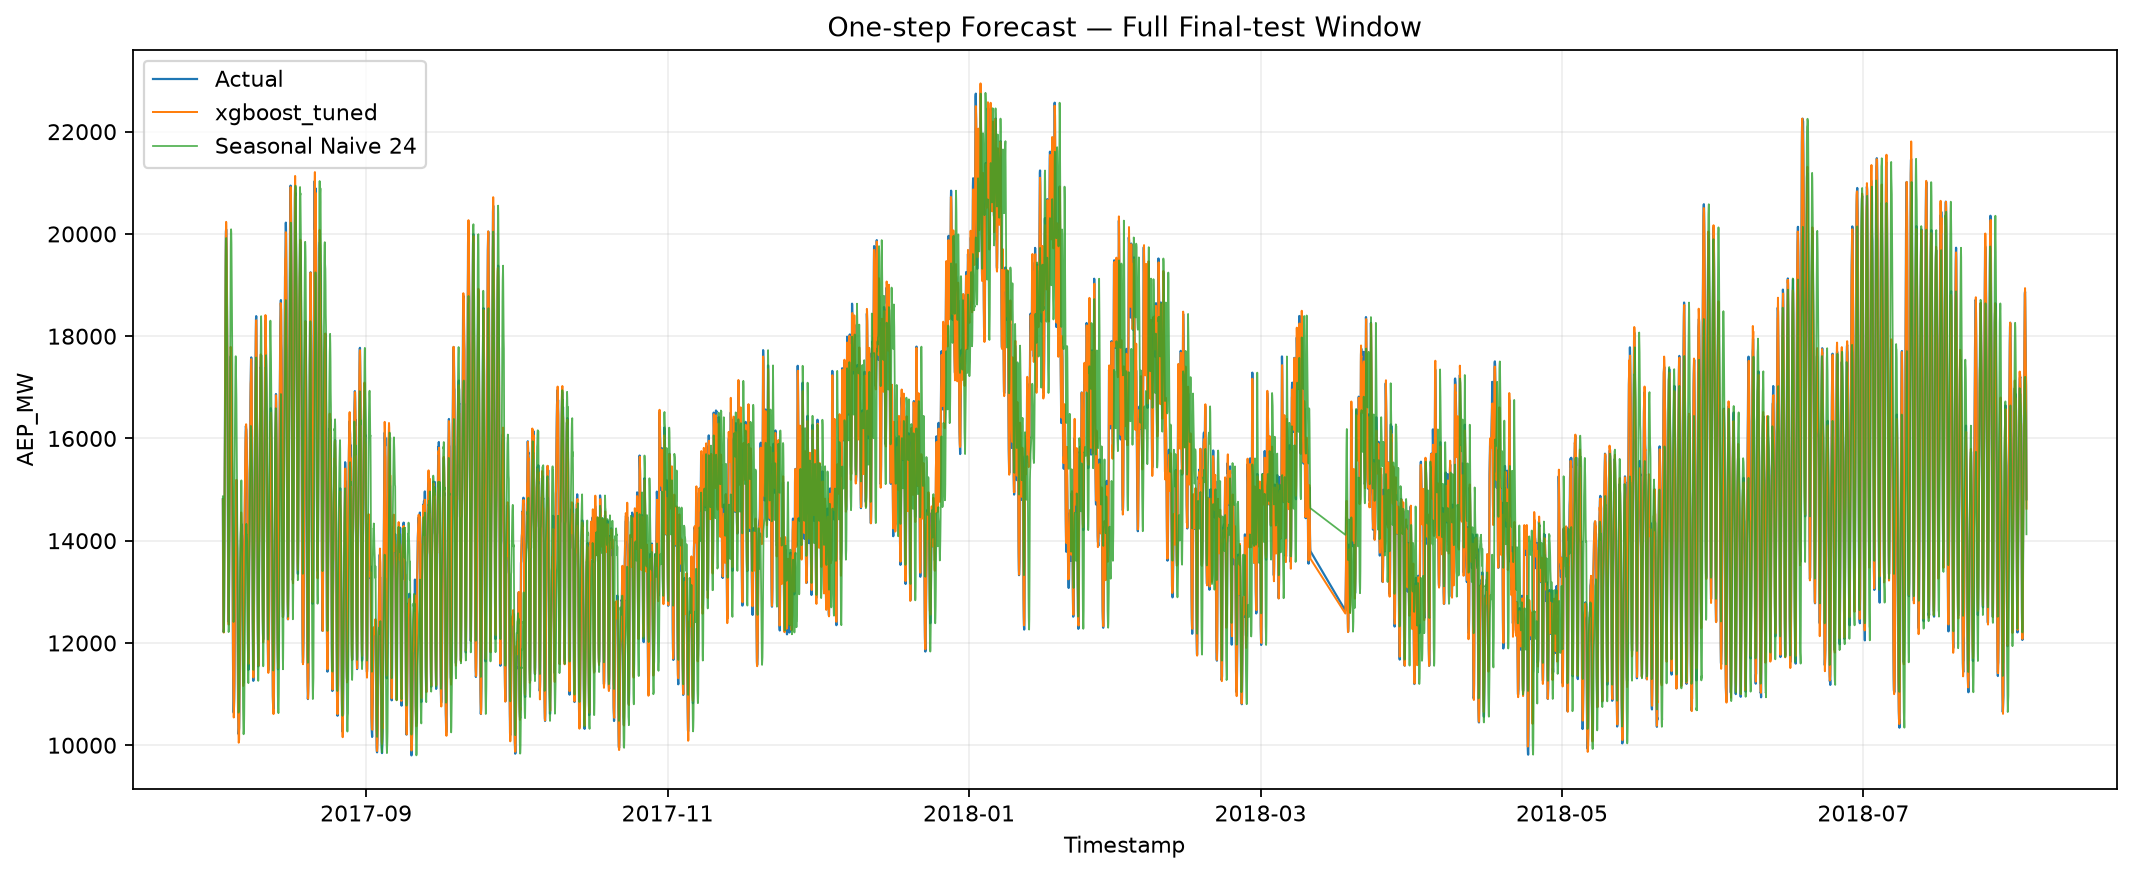

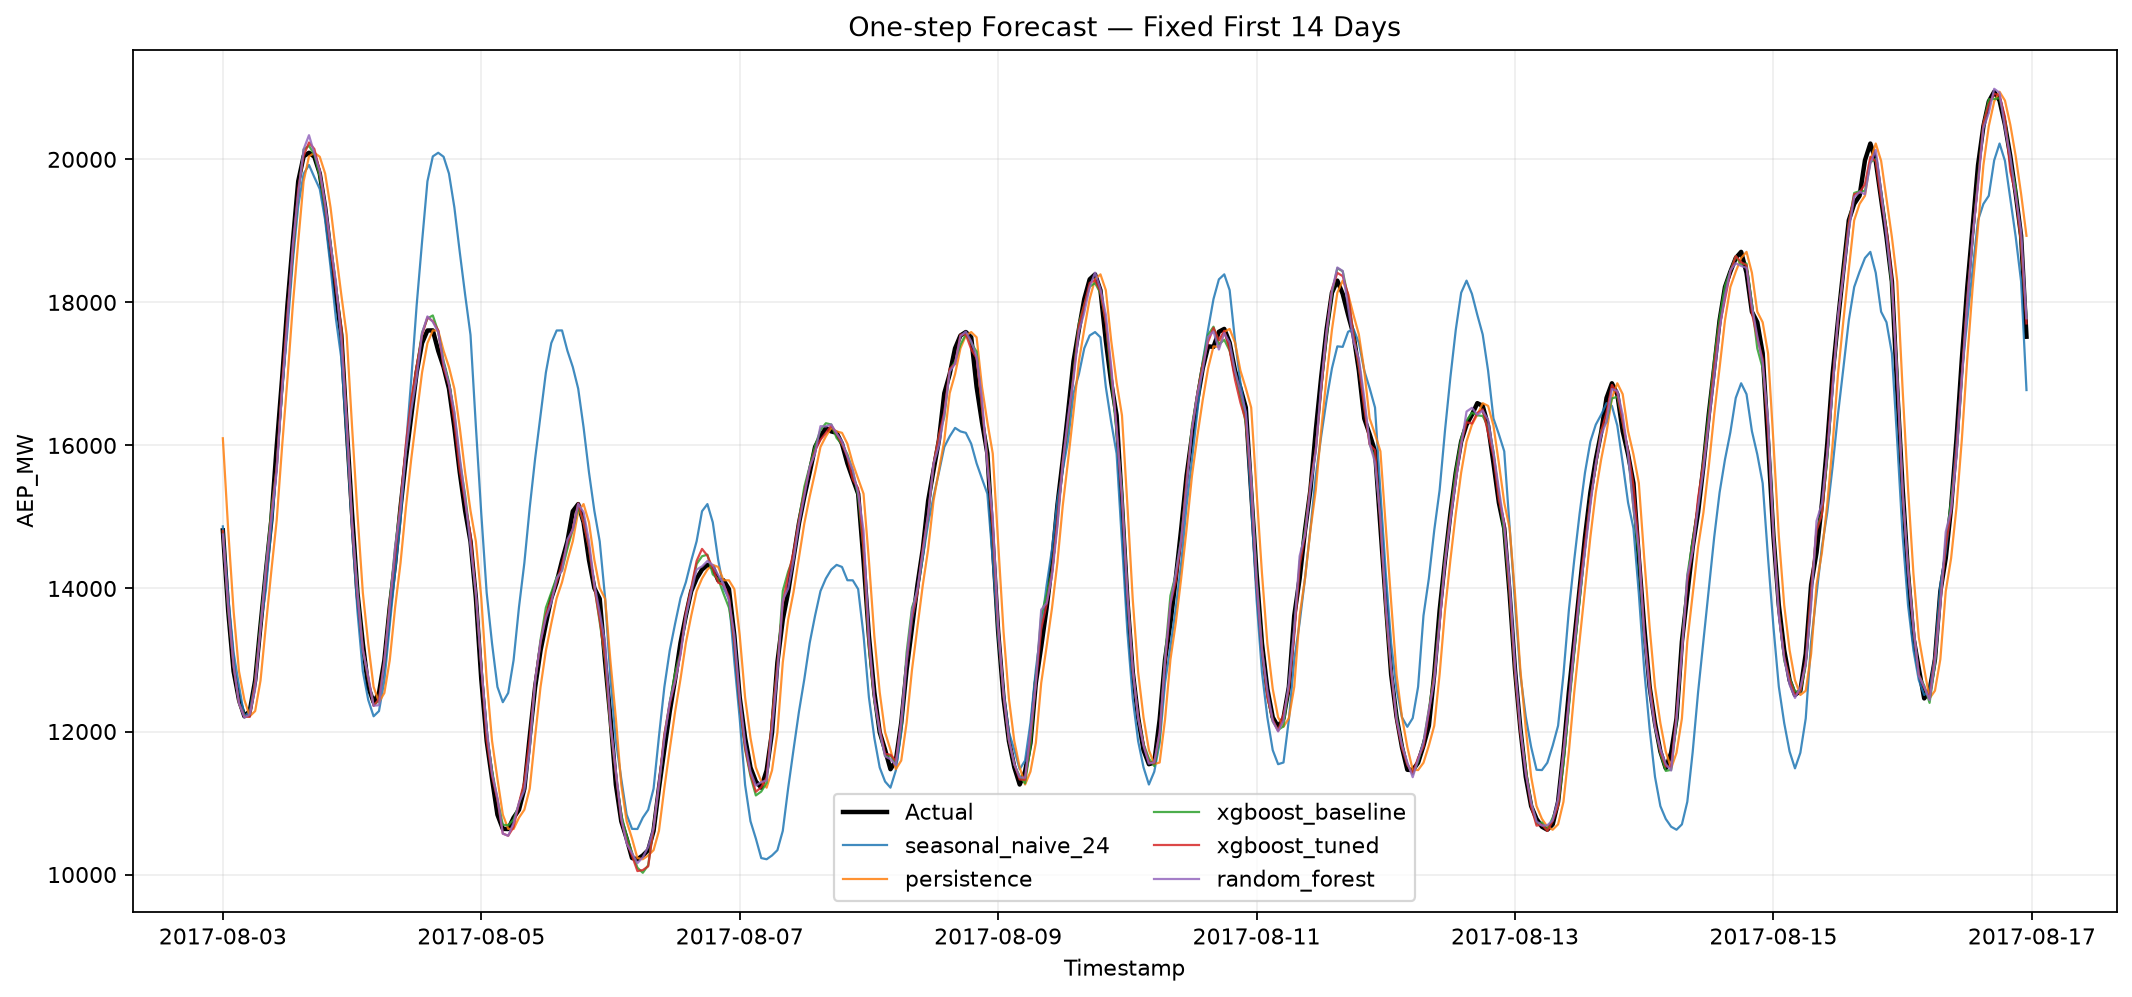

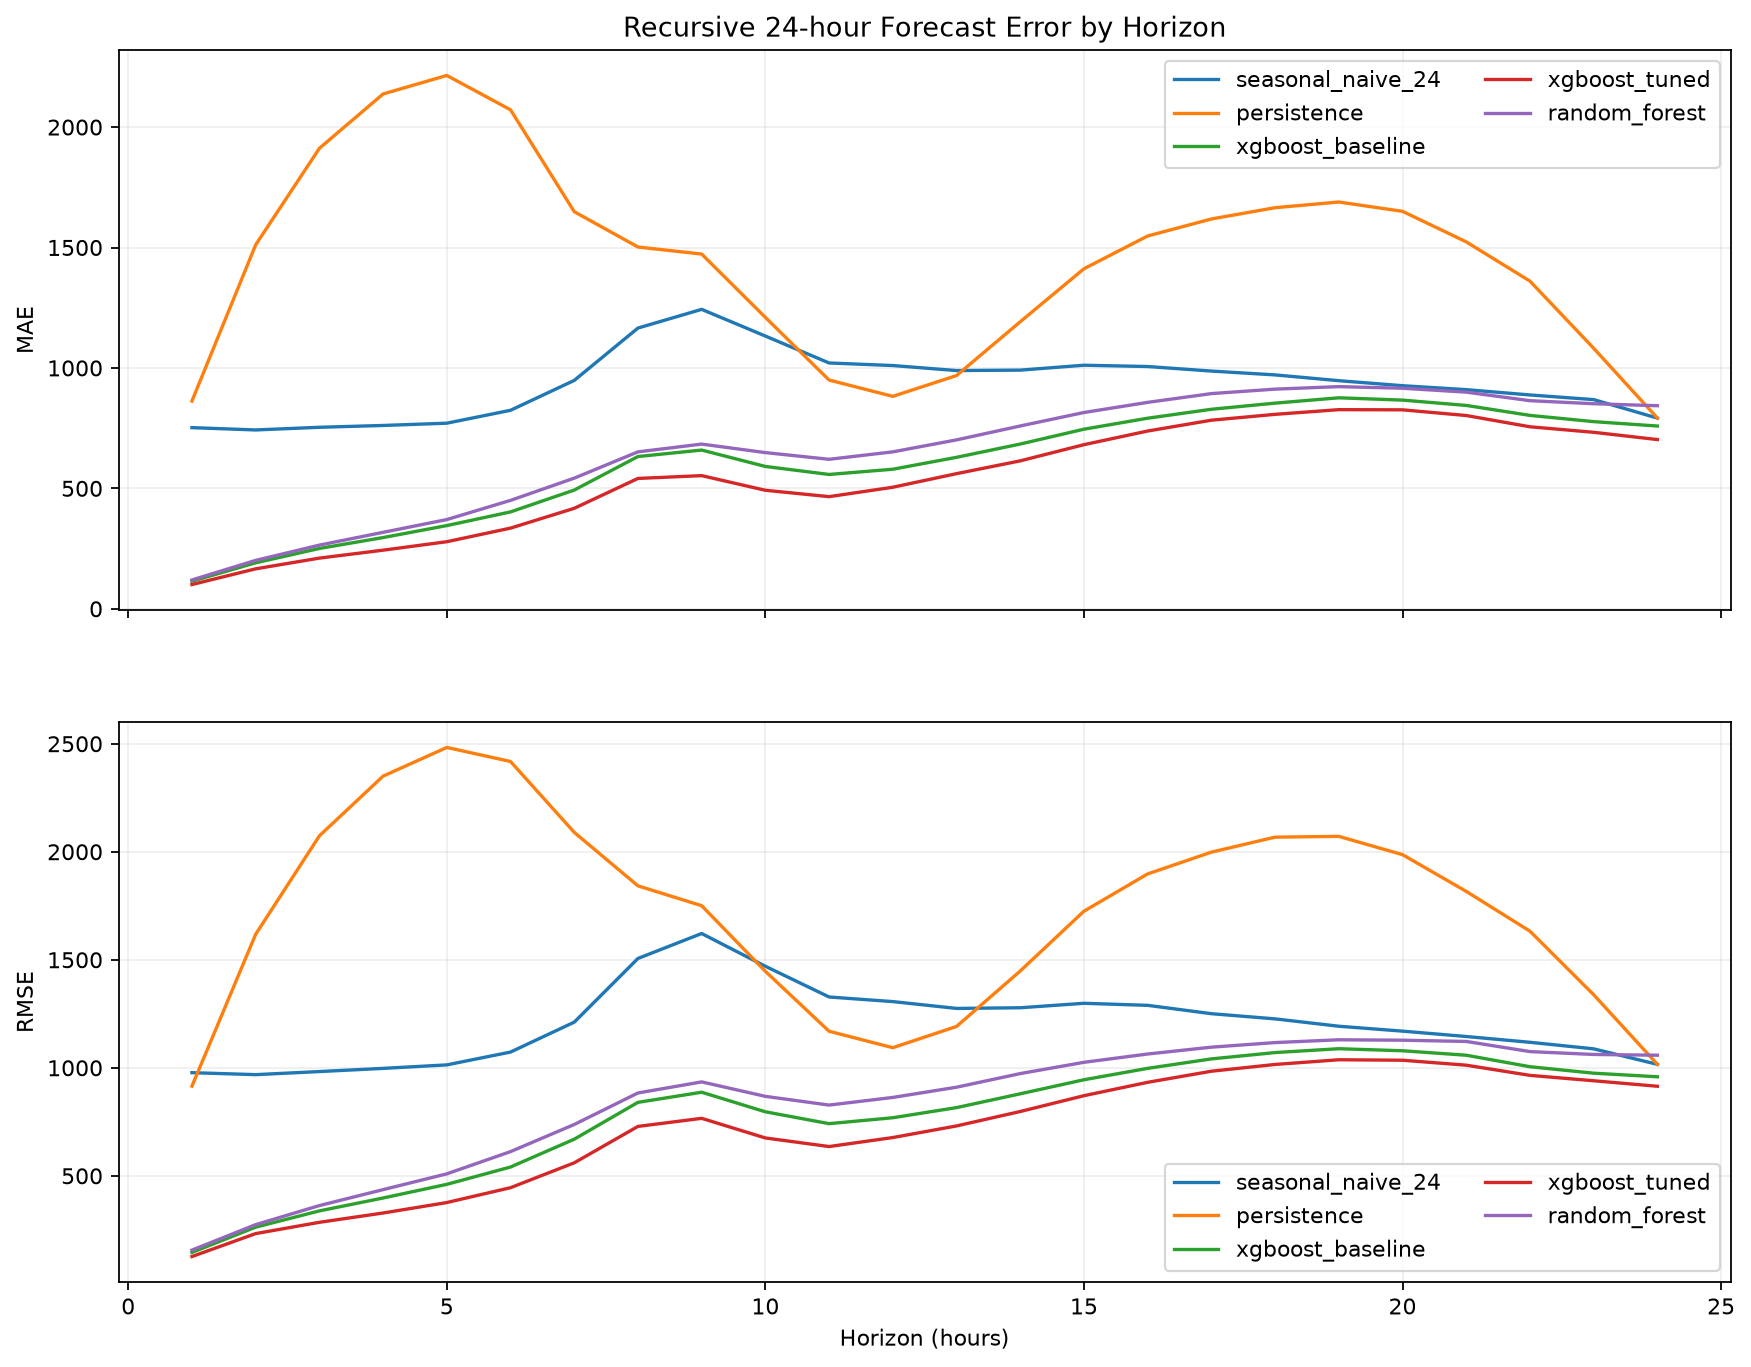

In [10]:
for figure_path in phase_06_figure_paths:
    display(Image(filename=str(figure_path)))

### Kết luận Phase 6

- `xgboost_tuned` có one-step MAE thấp nhất: **113,3278** và RMSE **150,2444** trên 8.592 timestamps.
- Trong recursive 24-hour evaluation, `xgboost_tuned` tiếp tục có pooled MAE thấp nhất: **547,5021** và pooled RMSE **763,0003**.
- Multi-step evaluation dùng **350/365 eligible origins**; 15 origins bị loại theo missing-block/history contract đã duyệt.
- One-step và multi-step là hai protocol khác nhau, vì vậy không gộp trực tiếp hai nhóm metric.
- Final test được mở đúng một lần; không có post-test model change.
- **Phase 6: PASS.**

## Phase 7 — Interpretation & Final Analysis

Phase 7 diễn giải evidence đã khóa từ Phase 5–6. Gain importance được lấy từ `xgboost_tuned` refit trên full TRAIN; không dùng final test để fit hoặc chọn lại model.

In [11]:
phase_07_summary = audits["phase_07_summary"]
phase_07_importance = pd.read_csv(phase_07_importance_path)
phase_07_comparison = pd.read_csv(phase_07_comparison_path)
phase_07_top10 = phase_07_importance.loc[:, ["rank", "feature", "normalized_gain"]].head(10).copy()
phase_07_top10["normalized_gain_percent"] = phase_07_top10.pop("normalized_gain") * 100
phase_07_top10 = phase_07_top10.rename(columns={"rank": "Rank", "feature": "Feature", "normalized_gain_percent": "Normalized gain (%)"}).round(4)
phase_07_rolling = pd.DataFrame(phase_07_summary["rolling_contribution"]).loc[:, ["p", "reference_mean_mae", "candidate_mean_mae", "relative_mae_improvement_percent", "classification"]]
phase_07_rolling = phase_07_rolling.rename(columns={"p": "Lag p", "reference_mean_mae": "Lag-only MAE", "candidate_mean_mae": "Lag + rolling MAE", "relative_mae_improvement_percent": "MAE improvement (%)", "classification": "Kết luận"}).round(4)
phase_07_model_summary = phase_07_comparison.loc[(phase_07_comparison["candidate_or_configuration"] == "xgboost_tuned") & (phase_07_comparison["comparison_group"] != "feature_configuration_screening"), ["evidence_scope", "forecast_protocol", "MAE", "RMSE", "relative_improvement_percent"]].copy()
phase_07_model_summary = phase_07_model_summary.rename(columns={"evidence_scope": "Evidence", "forecast_protocol": "Protocol", "relative_improvement_percent": "MAE improvement vs Seasonal Naive 24 (%)"}).round(4)
display(phase_07_top10)
display(phase_07_rolling)
display(phase_07_model_summary)

,Rank,Feature,Normalized gain (%)
0,1,lag_1,80.2177
1,2,lag_166,2.2978
2,3,lag_22,2.0535
3,4,lag_23,1.3454
4,5,lag_21,1.3235
5,6,lag_3,1.1900
6,7,lag_2,1.0218
7,8,lag_142,0.7598
8,9,lag_27,0.7117
9,10,lag_26,0.5762


,Lag p,Lag-only MAE,Lag + rolling MAE,MAE improvement (%),Kết luận
0,24,141.9273,141.3808,0.3850,NEUTRAL
1,72,134.9939,134.6228,0.2749,NEUTRAL
2,168,132.1500,131.7834,0.2774,NEUTRAL


,Evidence,Protocol,MAE,RMSE,MAE improvement vs Seasonal Naive 24 (%)
9,TRAIN_ONLY_CV,one_step,115.4782,151.3981,87.2078
14,FINAL_TEST,one_step_rolling_observed_history,113.3278,150.2444,87.8898
19,FINAL_TEST,recursive_24_hour,547.5021,763.0003,41.3679


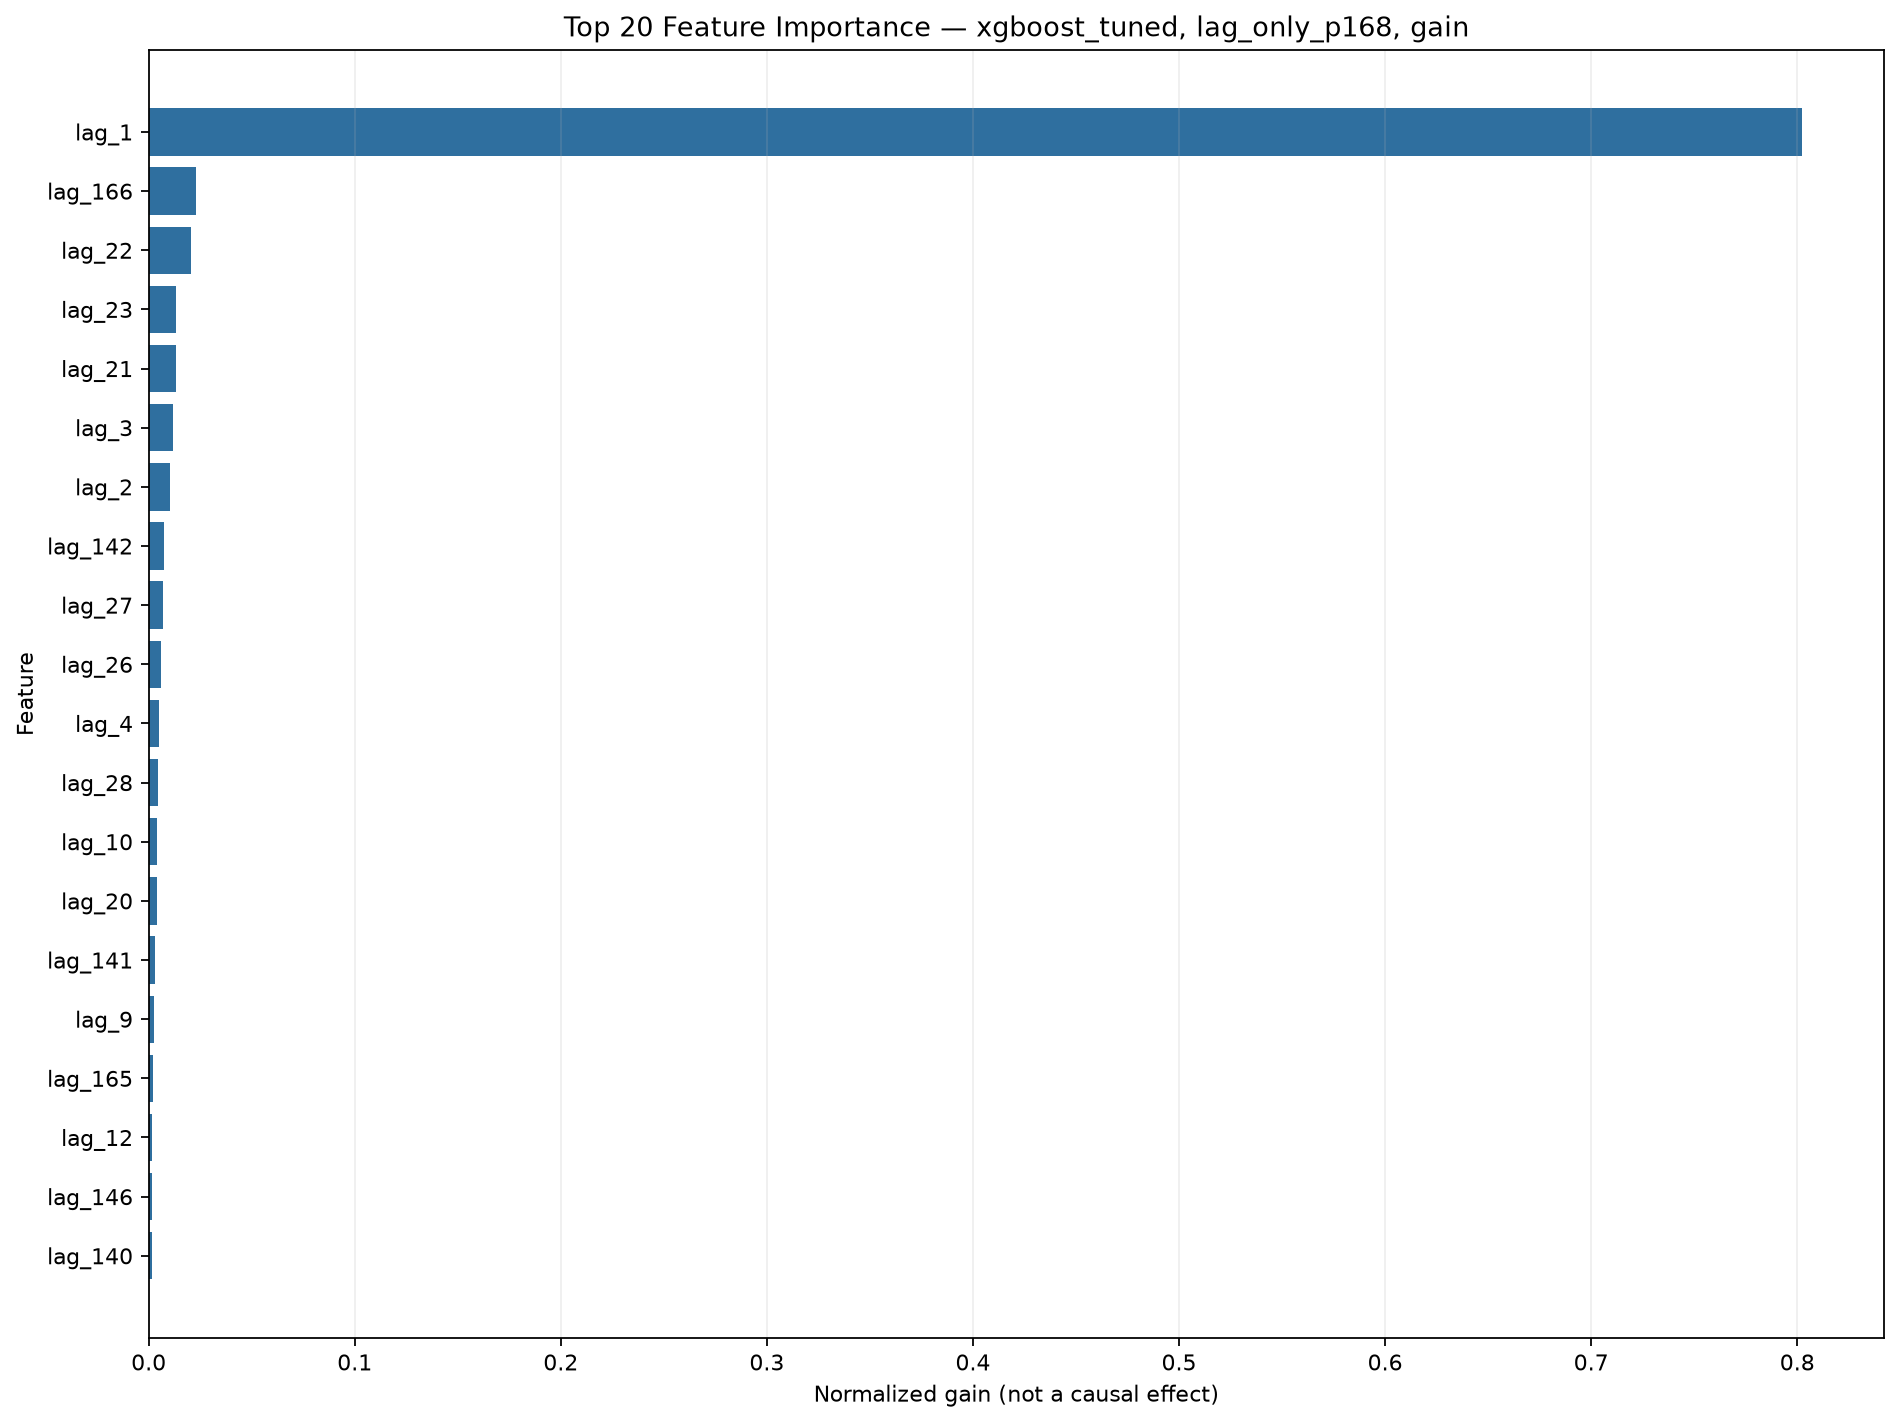

In [12]:
display(Image(filename=str(phase_07_figure_path)))

### Kết luận Phase 7

- `lag_1` đứng đầu với normalized gain khoảng **80,22%**, cho thấy short-term dependence mạnh trong fitted model; importance không chứng minh causality.
- Rolling features được phân loại **NEUTRAL** ở cả `p=24`, `p=72` và `p=168` theo ngưỡng ±1% trên TRAIN-only CV.
- `xgboost_tuned` được chọn bằng TRAIN-only CV và có MAE thấp nhất quan sát được ở cả one-step lẫn recursive 24-hour final-test protocol.
- Linear Regression và ARIMA chỉ được so sánh về lý thuyết vì không được train trong Practice 3.
- Recursive forecast có error accumulation; kết quả không được suy rộng ngoài final-test period.
- **Phase 7: PASS.**

## Tổng kết Phase 1–7

In [13]:
phase_summary = pd.DataFrame(
    [
        ["Phase 1", "Data Preparation", audits["phase_01"]["status"], "Timeline giờ đã chuẩn bị và có quality metadata"],
        ["Phase 2", "Feature Engineering", audits["phase_02"]["status"], "Lag và rolling features dùng lịch sử quá khứ"],
        ["Phase 3", "X/y Preparation", audits["phase_03"]["status"], "Sáu configurations dùng chung 116.675 mẫu"],
        ["Phase 4", "Temporal Split & Validation", audits["phase_04"]["status"], "Train/CV đã chốt; final test vẫn sealed"],
        ["Phase 5", "Model Training & Selection", audits["phase_05_lock"]["status"], "xgboost_tuned được khóa bằng TRAIN-only CV"],
        ["Phase 6", "Forecasting & Evaluation", audits["phase_06_audit"]["status"], "xgboost_tuned tốt nhất ở one-step và recursive 24-hour"],
        ["Phase 7", "Interpretation & Final Analysis", audits["phase_07_summary"]["status"], "lag_1 quan trọng nhất; kết luận giữ đúng evidence boundary"],
    ],
    columns=["Phase", "Phạm vi", "Trạng thái", "Kết quả chính"],
)
display(phase_summary)

,Phase,Phạm vi,Trạng thái,Kết quả chính
0,Phase 1,Data Preparation,PASS,Timeline giờ đã chuẩn bị và có quality metadata
1,Phase 2,Feature Engineering,PASS,Lag và rolling features dùng lịch sử quá khứ
2,Phase 3,X/y Preparation,PASS,Sáu configurations dùng chung 116.675 mẫu
3,Phase 4,Temporal Split & Validation,PASS,Train/CV đã chốt; final test vẫn sealed
4,Phase 5,Model Training & Selection,PASS,xgboost_tuned được khóa bằng TRAIN-only CV
5,Phase 6,Forecasting & Evaluation,PASS,xgboost_tuned tốt nhất ở one-step và recursive...
6,Phase 7,Interpretation & Final Analysis,PASS,lag_1 quan trọng nhất; kết luận giữ đúng evide...


### Trạng thái tiếp theo

Phase 1–7 đã hoàn thành và đều **PASS**. `xgboost_tuned` được chọn bằng TRAIN-only CV, có MAE thấp nhất quan sát được trên final test ở cả rolling one-step lẫn recursive 24-hour, và `lag_1` là feature có gain importance cao nhất. Bước tiếp theo là cập nhật README/navigation và thực hiện final repository readiness review sau khi Human duyệt phần trình bày này.